# Upper bound for the gravitatonal potential amplitude spectrum

This code illustrates ...

### Things we have to import

In [1]:
import pyvista as pv
pv.set_jupyter_backend('panel')

In [2]:
from PIL import Image

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from gravmag import eqlayer, filters, transforms, convolve, utils
from gravmag.models import rectangular_prism as rp
from gravmag import plot_functions as plf
from gravmag import constants as cts

In [4]:
from scipy.fft import fftshift

### Points were we compute the synthetic data

In [5]:
# number of points along x and y
shape = (60, 60)

# minimum x, maximum x, minimum y and maximum y
area = [-5000, 5000, -4000, 6000]

# coordinates 
xp = np.linspace(area[0], area[1], shape[0])
yp = np.linspace(area[2], area[3], shape[1])
yp, xp = np.meshgrid(yp, xp)

yp = np.ravel(yp)
xp = np.ravel(xp)

# constant vertical coordinate of the simulated gravity data
z_data = -150

zp = np.zeros_like(yp) + z_data

coordinates = np.vstack([xp, yp, zp])

In [6]:
# Grid spacing
dx = (area[1] - area[0])/(shape[0]-1)
dy = (area[3] - area[2])/(shape[1]-1)

In [7]:
print(dx, dy)

169.4915254237288 169.4915254237288


In [8]:
N_data = np.prod(shape)

### Main model

In [9]:
# Create a main model formed by a single prism
model_main = np.array([[-500, 500, 0, 2000, 150, 1010]])

density_main = np.array([2000]) # 2000 kg/m³ = 2 g/cm³

In [10]:
# scaled total mass of the main model
Omega_main = 2*np.pi*cts.GRAVITATIONAL_CONST*np.sum(density_main*utils.prisms_volume(model_main))

### Geological noise model

In [11]:
# center of Ns sources randomly distributed in the simulated area
Ngn = 300

xgn = area[0] + (area[1] - area[0])*np.random.rand(Ngn)
ygn = area[2] + (area[3] - area[2])*np.random.rand(Ngn)
zgn_top = 100.*np.random.rand(Ngn)

# sizes 
Lgn = 100. + 200*np.random.rand(Ngn)

# densities
density_gn = 2000. + 2000.*np.random.rand(Ngn)

# create the sources
model_gn = np.zeros((Ngn, 6))
model_gn[:,0] = xgn - 0.5*Lgn
model_gn[:,1] = xgn + 0.5*Lgn
model_gn[:,2] = ygn - 0.5*Lgn
model_gn[:,3] = ygn + 0.5*Lgn
model_gn[:,4] = 0.
model_gn[:,5] = zgn_top + Lgn

In [12]:
# scaled total mass of the geological noise model
Omega_gn = 2*np.pi*cts.GRAVITATIONAL_CONST*np.sum(density_gn*utils.prisms_volume(model_gn))

### Composite model

In [13]:
model = np.vstack([model_main, model_gn])

In [14]:
density = np.hstack([density_main, density_gn])

In [15]:
# scaled total mass of the composite model
Omega = Omega_main + Omega_gn

### Synthetic gravitational field

In [16]:
U_main = rp.grav(coordinates=coordinates, prisms=model_main, density=density_main, field='potential')

In [17]:
U_gn = rp.grav(coordinates=coordinates, prisms=model_gn, density=density_gn, field='potential')

In [18]:
U = U_main + U_gn

In [19]:
bounds = np.max(np.abs([U_main, U_gn, U]))

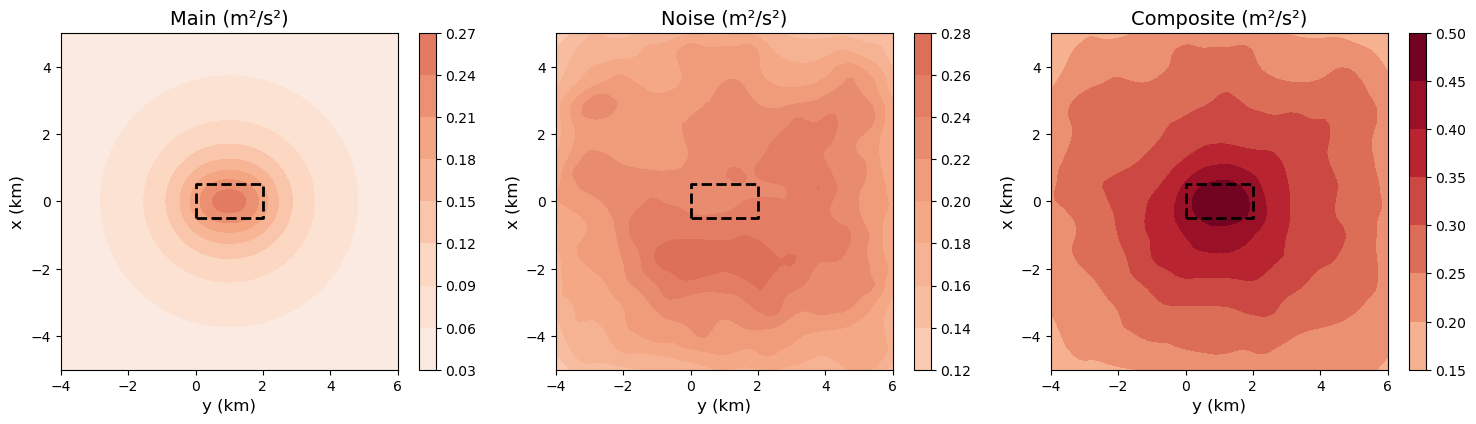

In [20]:
fields = [U_main, U_gn, U]

titles = ['Main (m²/s²)', 'Noise (m²/s²)', 'Composite (m²/s²)']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        yp.reshape(shape)*0.001, 
        xp.reshape(shape)*0.001, 
        fields[w].reshape(shape), 
        cmap='RdBu_r',
        vmin = -bounds, vmax = bounds
    )
    plt.colorbar()
    plf.model_boundaries(model_main, m2km=True)
    plt.ylim(0.001*area[0], 0.001*area[1])
    plt.xlim(0.001*area[2], 0.001*area[3])
    plt.xlabel('y (km)', fontsize=12)
    plt.ylabel('x (km)', fontsize=12)

plt.tight_layout()

plt.show()

### Theoretical bound for amplitude spectrum

In [21]:
# compute 2D Fourier transform of U without padding
FT_U = transforms.DFT(data=U.reshape(shape))

In [22]:
# multiply FT_U by the element of area to retrieve the true Fourier Transform amplitude
FT_U *= dx*dy

In [23]:
np.max(np.abs(FT_U))

29312067.75629458

In [30]:
# set the FT_U equal to zero at the zero frequency
FT_U[0,0] = 0.

In [31]:
np.max(np.abs(FT_U))

3122676.375059235

In [26]:
# compute wavenumbers
kx, ky, kz = transforms.wavenumbers(FT_U.shape, dx, dy)

In [37]:
# theoretical bound
kz[0,0] = 1
theoretical_bound = Omega*np.exp(-kz*(0. - z_data))/kz
theoretical_bound[0,0] = 0.
#theoretical_bound *= np.max(np.abs(FT_U))/np.max(theoretical_bound)
#theoretical_bound[0,0] = np.max(np.abs(FT_U))
kz[0,0] = 0

In [38]:
np.max(theoretical_bound)

9322951.063056368

In [39]:
assert np.all(theoretical_bound >= np.abs(FT_U))

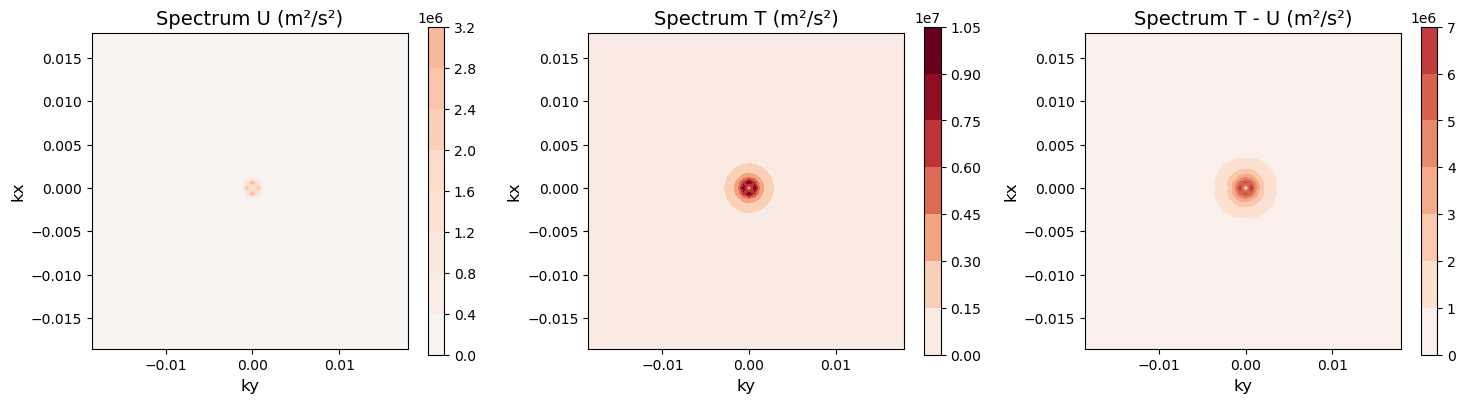

In [40]:
bounds = np.max(np.abs([np.abs(FT_U), 
                        theoretical_bound, 
                        theoretical_bound - np.abs(FT_U)]))

fields = [np.abs(FT_U), 
          theoretical_bound, 
          theoretical_bound - np.abs(FT_U)]

titles = ['Spectrum U (m²/s²)', 'Spectrum T (m²/s²)', 'Spectrum T - U (m²/s²)']

windows = [i for i in range(1,4)]

plt.figure(figsize=(15,4))

for w, window in enumerate(windows):

    plt.subplot(1,3,window)
    plt.title(titles[w], fontsize=14)
    plt.axis('scaled')
    plt.contourf(
        fftshift(ky), 
        fftshift(kx), 
        fftshift(fields[w]), 
        cmap='RdBu_r',
        vmin = -bounds, vmax = bounds
    )
    plt.colorbar()
    plt.ylim(kx.min(), kx.max())
    plt.xlim(ky.min(), ky.max())
    plt.xlabel('ky', fontsize=12)
    plt.ylabel('kx', fontsize=12)

plt.tight_layout()

plt.show()

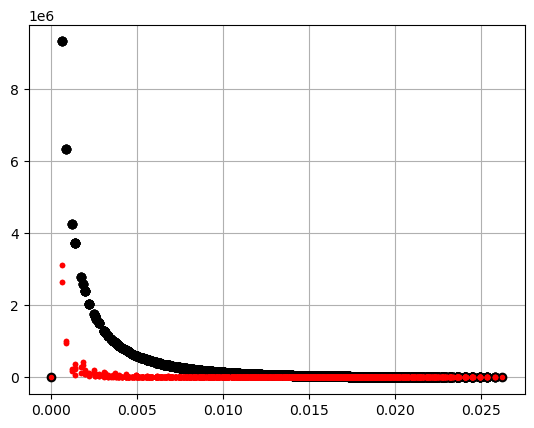

In [42]:
plt.figure()
plt.plot(kz.ravel(), theoretical_bound.ravel(), 'ko')
plt.plot(kz.ravel(), np.abs(FT_U).ravel(), 'r.')
plt.grid()
plt.show()

### Plot  and/or save the computed gravity disturbance and the model with PyVista

In [43]:
model_mesh = plf.prisms_to_pyvista(model, density)

In [44]:
pv.set_plot_theme('dark')

pl = pv.Plotter()

#parameters of model colorbar
model_sargs = dict(
    title='density (kg/m^3)',
    title_font_size=20,
    label_font_size=16,
    shadow=True,
    n_labels=7,
    italic=True,
    fmt="%.1f",
    font_family="arial",
)

# add model
pl.add_mesh(
    model_mesh,
    scalars='prop',
    cmap='viridis',
    lighting=True,
    scalar_bar_args=model_sargs,
    show_edges=True,
)

# set visualization parameters
# the order of the commands below changes the result
pl.camera_position = 'zy'
pl.camera.roll = -90
pl.camera.azimuth = 15
pl.camera.elevation = 30
pl.camera.zoom(1.1)

pl.show_axes()

# show the interactive plot
#pl.show()

# save the image in an external file
pl.screenshot('potential_amplitude_spectrum_bound.png', return_img=False)

### Plot the external image generated with PyVista

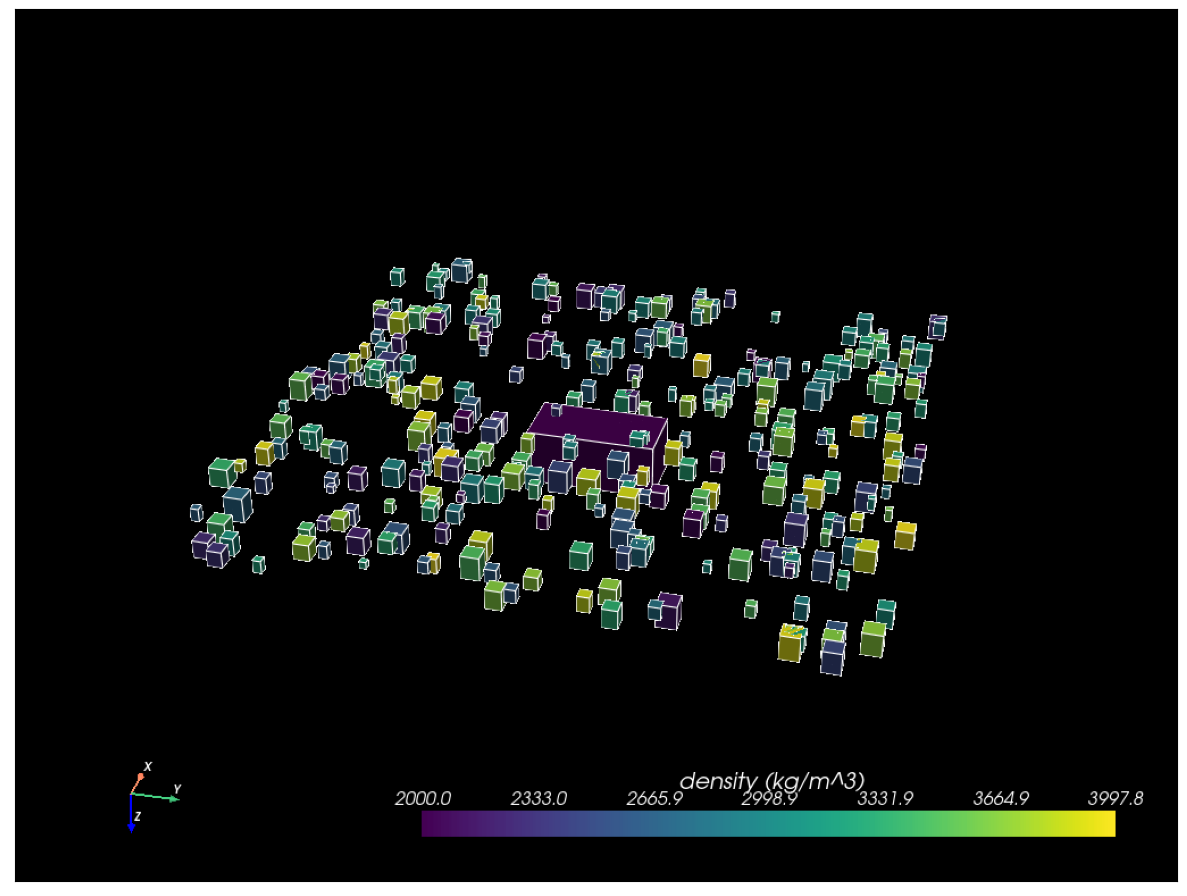

In [45]:
# read image generated with PyVista
image = Image.open('potential_amplitude_spectrum_bound.png')

# plot image generated with PyVista
plt.figure(figsize=(15,15))
plt.imshow(image)
plt.xticks([]) # remove x ticks
plt.yticks([]) # remove y ticks
plt.show()